# Inference : classification (BioCLIP) + CAM + segmentation SAM sur MINKA

Pipeline pour une photo MINKA :
1. **Classification** de la famille avec le modèle **BioCLIP déjà fine-tuné** (`best_family_bioclip.pth`) ;
2. **CAM** (Grad-CAM adapté au ViT de BioCLIP) pour la famille prédite ;
3. **SAM** : les points les plus chauds de la CAM servent de prompts pour obtenir un masque précis de l'organisme.

## For Google Collab Only

In [1]:
import os, sys

if "google.colab" in sys.modules:
    if not os.path.exists("ANERIS_BrugesWORKSHOP"):
        !git clone https://github.com/PerrineGilloteaux/ANERIS_BrugesWORKSHOP.git
    %cd ANERIS_BrugesWORKSHOP
    !pip install -q -r requirementsColab.txt

Cloning into 'ANERIS_BrugesWORKSHOP'...
remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (39/39), done.
remote: Compressing objects: 100% (33/33), done.
remote: Total 39 (delta 19), reused 15 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (39/39), 408.07 KiB | 18.55 MiB/s, done.
Resolving deltas: 100% (19/19), done.
/content/ANERIS_BrugesWORKSHOP


## 1. Loading once the models (BioCLIP + SAM)

In [6]:
import os, time, urllib.request
import numpy as np
import torch
import cv2
import matplotlib.pyplot as plt
import torchvision.transforms as transforms

from AEIS_MAC_libforminka import (
    read_image, load_model_from_checkpoint, load_predictor,
    refine_mask_with_sam, display_results,
    _preprocess, _model_transform, _normalize_stats, download_if_missing, analyse_image
)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device :", device)

# --- Fichiers (téléchargés une seule fois s'ils sont absents) ---
MODEL_PATH = "models/best_family_bioclip.pth"
MODEL_URL  = "https://zenodo.org/records/23236454/files/best_family_bioclip.pth?download=1"
SAM_PATH   = "sam_vit_h_4b8939.pth"
SAM_URL    = "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth"


download_if_missing(MODEL_URL, MODEL_PATH)
download_if_missing(SAM_URL, SAM_PATH)

# --- BioCLIP fine-tuné (le checkpoint contient la config, les poids et la liste des familles) ---
model, _, epoch, _, class_names = load_model_from_checkpoint(MODEL_PATH, device=device)
model.eval()
if class_names is None:                      # sécurité : ancien checkpoint sans class_names
    import pickle
    class_names = pickle.load(open("labels_and_encoder.pkl", "rb"))["class_names"]
print(f"{type(model).__name__} chargé (epoch {epoch + 1}), {len(class_names)} familles")

# --- SAM (sur GPU si disponible : load_predictor le laisse sur CPU) ---
predictor = load_predictor(SAM_PATH)
predictor.model.to(device)
print("SAM chargé")

Device : cuda:0
Téléchargement de models/best_family_bioclip.pth ...
Téléchargement de sam_vit_h_4b8939.pth ...


open_clip_config.json:   0%|          | 0.00/469 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

BioCLIPClassifier chargé (epoch 8), 365 familles
SAM chargé


## 2. Inference

Look for a picture on the MINKA database , and click on the "i" to get the picture number, copy paste it under PHOTO_IDS

`TH` is the threshold on the selectivity of the CAM (between 0 all and 1 nothing)

`B` is the block/ layer of attention where to look at (-3 to 1 usually)

Échec : https://observe.minka-sdg.org/attachments/local_photos/files/956547/medium.jpg
Image OK : https://observe.minka-sdg.org/attachments/local_photos/files/956547/medium.jpeg
Famille prédite : Aeolidiidae (85.3%)
   alternative : Acanthochitonidae (0.4%)
   alternative : Facelinidae (0.4%)
Temps : classification 6.2s | CAM 0.5s | SAM 2.2s
mask Area : 77207 pixels | Image Area : 187500 pixels | Ratio : 0.4118 (41.18%)


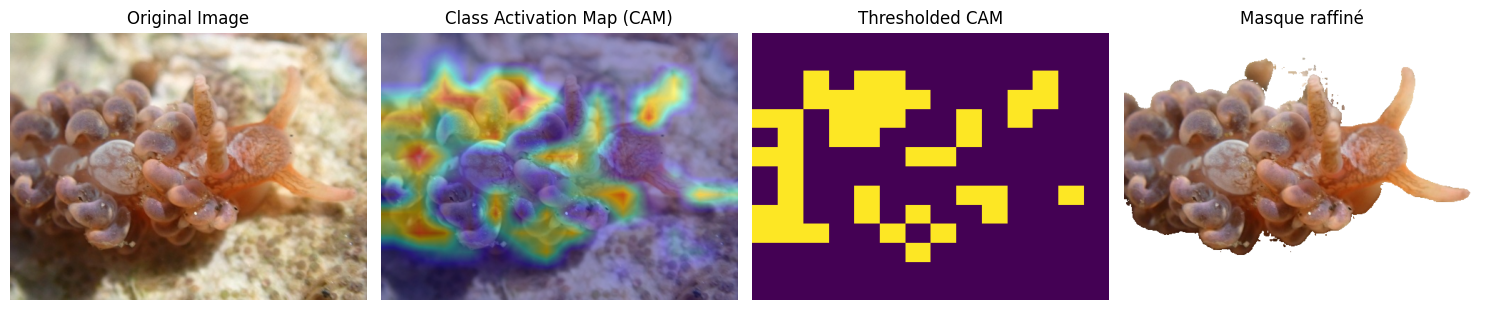

In [7]:
PHOTO_IDS = ["956547"]     # numéros de photo MINKA (ou URL complète, ou chemin local)
TH = 0.5                # seuil CAM -> points SAM
B=-2
results = {}
for pid in PHOTO_IDS:
    results[pid] = analyse_image(pid, model, device, class_names, predictor, th=TH, block=B )

With an uploaded Jpeg

In [5]:
import io
import ipywidgets as widgets
from IPython.display import display, Image, clear_output

# Création du bouton de glisser-déposer / téléchargement
uploader = widgets.FileUpload(
    accept='.jpeg,.jpg',
    multiple=False,  # Une seule image à la fois
    description='Glisser ou Charger'
)

# Zone de sortie pour afficher l'image une fois chargée
output = widgets.Output()

def on_value_change(change):
    with output:
        clear_output()
        if not uploader.value:
            return

        # Récupération de l'image
        uploaded_file = list(uploader.value.values())[0]
        content = uploaded_file['content']

        # Sauvegarde locale de l'image sous le nom 'uploaded_image.jpg' pour les étapes suivantes de votre pipeline
        with open("uploaded_image.jpg", "wb") as f:
            f.write(content)

        print(f"Image loaded and saved under 'uploaded_image.jpg' !")
        display(Image(data=content, width=300))

uploader.observe(on_value_change, names='value')

# Affichage du widget
display(widgets.VBox([uploader, output]))

Analyse de l'image locale : uploaded_image.jpg...
Image OK : uploaded_image.jpg
Famille prédite : Laridae (86.6%)
   alternative : Alcidae (0.2%)
   alternative : Crambidae (0.2%)
Temps : classification 0.0s | CAM 0.1s | SAM 2.0s
mask Area : 67518 pixels | Image Area : 749760 pixels | Ratio : 0.0901 (9.01%)


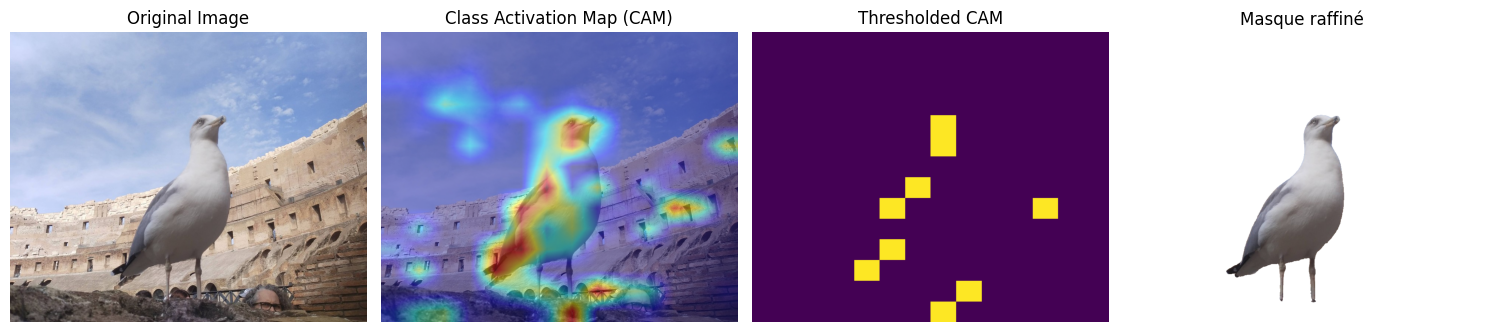

In [11]:
# Analyser l'image locale que vous venez d'uploader via le bouton glisser-déposer
import os

local_image_path = "uploaded_image.jpg"
TH = 0.8  # Seuil de sélectivité de la CAM (entre 0 et 1)
B = -1   # Couche d'attention

if os.path.exists(local_image_path):
    print(f"Analyse de l'image locale : {local_image_path}...")
    results = analyse_image(local_image_path, model, device, class_names, predictor, th=TH, block=B)
else:
    print(f"Erreur : Le fichier '{local_image_path}' est introuvable. Veuillez d'abord glisser-déposer une image dans le widget ci-dessus.")